In [1]:
import time
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint
from scipy.stats import ttest_rel

pd.set_option("display.width", 140)

In [2]:
UNIVERSE = ["BTC", "ETH", "SOL", "BNB", "XRP", "DOGE", "ADA", "LINK", "AVAX", "DOT", 
            "LTC", "ATOM", "AAVE", "UNI", "ARB", "OP", "SUI", "NEAR", "ALGO", "FIL", 
            "MATIC", "TRX", "BCH", "ETC", "XLM", "ICP", "APT", "SEI", "INJ", "RENDER", 
            "FET", "TIA", "HBAR", "VET", "THETA", "EOS", "SAND", "MANA", "GRT", "MKR"]
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [ ]:
exchange = ccxt.coinbase({"enableRateLimit": True, "timeout": 30000})
markets = exchange.load_markets()

symbols = [f"{coin}/USD" for coin in UNIVERSE if f"{coin}/USD" in markets]
pairs = list(combinations(symbols, 2))
print(f"{len(symbols)} coins available, {len(pairs)} candidate pairs")

37 coins available, 666 candidate pairs


In [ ]:
# ----------------------------------------------
# Format timestamp column; rename df columns function
# ----------------------------------------------

def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close", "volume"]].copy()
    df = df.rename(columns={"close": symbol, "volume": f"{symbol}_volume"})
    return df

In [ ]:
# ----------------------------------------------
# Fetch market data function
# ----------------------------------------------
def fetch_ohlcv_history(exchange, symbol, timeframe, since_ms, limit=300, max_retries=5):
    all_rows = []
    since = since_ms
    now_ms = exchange.milliseconds()

    while since < now_ms:
        batch = None
        for attempt in range(max_retries):
            try:
                batch = exchange.fetch_ohlcv(symbol, timeframe=timeframe, since=since, limit=limit)
                break
            except (ccxt.RequestTimeout, ccxt.NetworkError) as e:
                if attempt == max_retries - 1:
                    raise
                time.sleep(2 ** attempt)

        if not batch:
            break

        all_rows.extend(batch)
        since = batch[-1][0] + 1

    return all_rows

In [6]:
# ----------------------------------------------
# Fetch price data for each coin in universe
# ----------------------------------------------

YEARS_OF_HISTORY = 5 
TIMEFRAME = "1h"

since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)
HISTORY_SINCE = exchange.parse8601(since_dt.strftime("%Y-%m-%dT%H:%M:%SZ"))

prices = None
for coin in UNIVERSE:
    symbol = f"{coin}/USD"
    if symbol not in markets:
        continue
    data = fetch_ohlcv_history(exchange, symbol, timeframe=TIMEFRAME, since_ms=HISTORY_SINCE)
    if not data:
        continue
    df = to_df(data, coin)
    prices = df if prices is None else prices.merge(df, on="timestamp", how="inner")

prices = prices.sort_values("timestamp").reset_index(drop=True)
print(f"{len(prices)} aligned hourly bars, {prices['timestamp'].min()} -> {prices['timestamp'].max()}")

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_59904/1113893799.py:8: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)


37721 aligned hourly bars, 2021-08-19 22:00:00 -> 2025-12-10 19:00:00


In [188]:
# Keep the original 1h data so we can compare 4h / 8h / 12h later.
prices_1h = prices.copy()

# Main run stays at 4h, just like the original notebook.
prices = prices_1h.set_index("timestamp").resample("4h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

In [189]:
# What coins had available data out of the original universe
available_assets = [c for c in UNIVERSE if c in prices.columns]
symbols = [f"{c}/USD" for c in available_assets]
pairs = list(combinations(symbols, 2))

In [190]:
# ----------------------------------------------
# Split price data into train and test (70/30)
# ----------------------------------------------
TRAIN_FRAC = 0.7

split_idx = int(len(prices) * TRAIN_FRAC)
train_prices = prices.iloc[:split_idx].reset_index(drop=True)
test_prices = prices.iloc[split_idx:].reset_index(drop=True)

print(f"Train: {train_prices['timestamp'].min()} -> {train_prices['timestamp'].max()}  ({len(train_prices)} bars)")
print(f"Test:  {test_prices['timestamp'].min()} -> {test_prices['timestamp'].max()}  ({len(test_prices)} bars)")

Train: 2021-08-19 20:00:00 -> 2024-08-25 08:00:00  (6610 bars)
Test:  2024-08-25 12:00:00 -> 2025-12-10 16:00:00  (2833 bars)


In [191]:
# ----------------------------------------------
# Align timestamp for price data of 2 assets
# ----------------------------------------------
def align_pair_prices(prices, asset_a, asset_b):
    cols = ["timestamp", asset_a, asset_b]
    vol_cols = [f"{asset_a}_volume", f"{asset_b}_volume"]
    needed = cols + [c for c in vol_cols if c in prices.columns]
    out = prices[needed].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [192]:
# ----------------------------------------------
# Regress log prices of assets to get alpha, beta, corr, and EG function
# ----------------------------------------------
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Fit the hedge ratio via OLS (used ONLY on the train set) and run the
    Engle-Granger cointegration test on the two log-price series.
    Two nonstationary series can produce a highly significant OLS slope
    just because both trend -- that p-value is NOT a cointegration test,
    so we report the Engle-Granger p-value instead.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]
    model = sm.OLS(y, X).fit()
    
    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]
    out["spread"] = model.resid

    eg_stat, eg_pvalue, eg_crit = coint(out[f"log_{asset_a}"], out[f"log_{asset_b}"])

    return out, alpha, beta, corr, eg_pvalue

In [193]:
# ----------------------------------------------
# Compute spread on test data function
# ----------------------------------------------
def apply_fixed_spread(df, asset_a, asset_b, alpha, beta):
    """
    Build the spread on a NEW sample (e.g. the test set) using an alpha/beta
    that was already estimated elsewhere (the train set). No refitting here,
    so no look-ahead when this is used out-of-sample.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])
    out["spread"] = out[f"log_{asset_a}"] - (alpha + beta * out[f"log_{asset_b}"])
    return out

In [194]:
# ----------------------------------------------
# Compute spread halflife function
# ----------------------------------------------
def spread_half_life(spread):
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag
    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]
    if len(tmp) < 5:
        return np.nan
    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]
    if lam >= 0:
        return np.nan
    return -np.log(2) / lam

In [195]:
# ----------------------------------------------
# Count number of Z-score crossings function
# ----------------------------------------------
def spread_crossings(z, threshold=2.0):
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0
    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [196]:
# ----------------------------------------------
# Compute beta stability function
# ----------------------------------------------
def simple_beta_stability(df, asset_a, asset_b):
    """Compare the hedge ratio in the first half vs second half of training data."""
    mid = len(df) // 2
    if mid < 20:
        return np.nan

    def get_beta(x):
        la = np.log(x[asset_a])
        lb = np.log(x[asset_b])
        return sm.OLS(la, sm.add_constant(lb)).fit().params.iloc[1]

    b1 = get_beta(df.iloc[:mid])
    b2 = get_beta(df.iloc[mid:])
    if b1 == 0 or np.isnan(b1) or np.isnan(b2):
        return np.nan
    return abs(b2 - b1) / abs(b1)

In [197]:
# ----------------------------------------------
# Calculate and display pair summary function
# ----------------------------------------------
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    df, alpha, beta, corr, eg_pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)
    beta_stability = simple_beta_stability(df, asset_a, asset_b)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "EG_Coint_Pvalue": eg_pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread_Vol": spread_vol,
        "Half_life": hl,
        "Z_score_Crossings": crossings,
        "Beta_Stability": beta_stability})

In [198]:
# ----------------------------------------------
# Select base pairs function
# Get pair summary for each candidate pair using train data
# Query results to filter unwanted pairs
# Result: Base list of viable pairs
# ----------------------------------------------
def select_base_pairs(prices_train, pairs, max_candidates=20):
    """
    Static pair screening for the TRAINING period only.

    Important:
    This is recalculated separately for each timeframe so that
    Alpha/Beta and all screening statistics belong to that timeframe.
    """
    candidate_rows = []

    for a, b in pairs:
        candidate_rows.append(pair_summary(prices_train, a.split("/")[0], b.split("/")[0]))

    pair_table = pd.DataFrame(candidate_rows)

    eligible = pair_table.query("Corr > 0.8")
    eligible = eligible.query("EG_Coint_Pvalue < 0.1")
    eligible = eligible.query("Half_life >= 12 and Half_life <= 600")
    eligible = eligible.query("Beta_Stability <= 0.35")

    eligible = (eligible.sort_values("Z_score_Crossings", ascending=False).reset_index(drop=True))

    return eligible.head(max_candidates).reset_index(drop=True)


In [199]:
# ----------------------------------------------
# Get base pairs
# ----------------------------------------------
# base_pairs = select_base_pairs(train_prices, pairs, max_candidates=50)
# print(f"{len(base_pairs)} pairs passed the statistical screen")
# base_pairs.head(10)


In [200]:
# ----------------------------------------------
# Compute rolling Z-score function
# ----------------------------------------------
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [201]:
# ----------------------------------------------
# Create Z-score positions per timestamp
# ----------------------------------------------
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25, min_persist=4, cooldown_bars=0, allow_entry=None):
    position = 0
    cooldown = 0
    below_count = 0
    above_count = 0
    positions = []

    for i, val in enumerate(z):
        if pd.isna(val):
            positions.append(0)
            continue

        if val < -entry_z:
            below_count += 1
        else:
            below_count = 0

        if val > entry_z:
            above_count += 1
        else:
            above_count = 0

        if cooldown > 0:
            cooldown -= 1

        entry_ok = True if allow_entry is None else bool(allow_entry.iloc[i])

        if position == 0:
            if cooldown == 0 and entry_ok and below_count >= min_persist:
                position = 1
            elif cooldown == 0 and entry_ok and above_count >= min_persist:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0
                cooldown = cooldown_bars

        elif position == -1:
            if val < exit_z:
                position = 0
                cooldown = cooldown_bars

        positions.append(position)

    return pd.Series(positions, index=z.index)

In [ ]:
# ----------------------------------------------
# Main backteset function - Z-score focus
# Align pair prices
# Apply fixed spread
# Apply low vollume filter
# Rolling Z-score
# Build Z-score positions
# Calculate metrics
# ----------------------------------------------
def backtest_pair_strategy(
    prices, asset_a, asset_b, alpha, beta, ann_factor_hourly,
    window, entry_z, exit_z, fee_bps,
    min_persist, cooldown_bars, vol_window):

    df = align_pair_prices(prices, asset_a, asset_b)
    df = apply_fixed_spread(df, asset_a, asset_b, alpha, beta)

    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    # Simple volume idea:
    # low relative volume -> 1.25x exposure
    # normal volume      -> 1.00x exposure
    # high volume        -> 0.50x exposure
    # very high volume   -> 0x exposure
    vol_a = f"{asset_a}_volume"
    vol_b = f"{asset_b}_volume"
    if vol_a in df.columns and vol_b in df.columns:
        rel_a = df[vol_a] / df[vol_a].rolling(vol_window).median()
        rel_b = df[vol_b] / df[vol_b].rolling(vol_window).median()
        df["relative_volume"] = (rel_a + rel_b) / 2
        vol_mean = df["relative_volume"].rolling(vol_window).mean()
        vol_std = df["relative_volume"].rolling(vol_window).std()
        df["volume_z"] = (df["relative_volume"] - vol_mean) / vol_std
        df["volume_scale"] = np.where(
            df["volume_z"] >= 2.0, 0.0,
            np.where(df["volume_z"] >= 1.0, 0.5,
                     np.where(df["volume_z"] <= -1.0, 1.25, 1.0)))
        df["volume_ok"] = df["volume_scale"] > 0
    else:
        df["volume_scale"] = 1.0
        df["volume_ok"] = True

    df["zscore"] = rolling_zscore(df["spread"], window=window)
    allow_entry = df["volume_ok"] 

    # z_smooth = df["zscore"].rolling(3).mean()

    df["position"] = build_zscore_positions(
        df["zscore"], entry_z=entry_z, exit_z=exit_z,
        min_persist=min_persist, cooldown_bars=cooldown_bars,
        allow_entry=allow_entry
    )

    # Adjust exposure using the volume signal.
    df["position"] = df["position"] * df["volume_scale"]

    gross = 1 + abs(beta)
    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )
    df["raw_ret"] = raw_ret

    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )
    df["turnover"] = turnover

    cost_per_turn = fee_bps / 10000.0
    df["strategy_ret"] = raw_ret - turnover * cost_per_turn
    gross_sharpe = (
        raw_ret.mean() / raw_ret.std()
    ) * ann_factor_hourly if raw_ret.std() != 0 and not np.isnan(raw_ret.std()) else np.nan

    df = df.set_index("timestamp")
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    r = df["strategy_ret"].dropna()
    sharpe = (r.mean() / r.std()) * ann_factor_hourly if r.std() not in (0,) and not np.isnan(r.std()) else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1 if len(df) else np.nan
    trades = (df["position"].diff().fillna(0) != 0).sum()

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}", 
        "Alpha": alpha, "Beta": beta, "Gross Sharpe": gross_sharpe, "Sharpe": sharpe,
        "Cumulative Return": cum_ret, "Max Drawdown": max_dd,
        "Trades": int(trades), "Avg Turnover/Bar": turnover.mean(),
        "Mean Hourly Return": r.mean(), "Vol Hourly": r.std(),
    })
    return df, metrics

In [298]:
# ----------------------------------------------
# Define hyperparameters
# Run pairs backtest function
# ----------------------------------------------
ANN_FACTOR_HOURLY = 6
FEE_BPS_MAIN = 20.0  
WINDOW = 25  
Z_ENTRY = 2.5
Z_EXIT = 0.5
MIN_PERSIST = 2
COOLDOWN_BARS = 0
VOL_WINDOW = 50

def run_pairs(prices_slice, selected_pairs, param_value, fee_bps, timeframe_hours,
              window=WINDOW, exit_z=Z_EXIT, min_persist=MIN_PERSIST, 
              cooldown_bars=COOLDOWN_BARS, vol_window=VOL_WINDOW,):
    ann_factor = np.sqrt(365 * 24 / timeframe_hours)
    bts = {}
    ret_series = {}
    metrics_rows = []

    for _, row in selected_pairs.iterrows():
        a, b = row["Asset_A"], row["Asset_B"]
        kwargs = dict(
            window=window,
            fee_bps=fee_bps,
            min_persist=min_persist,
            cooldown_bars=cooldown_bars,
            vol_window=vol_window)

        kwargs.update(entry_z=param_value, exit_z=exit_z)

        bt, m = backtest_pair_strategy(
            prices_slice, a, b,
            alpha=row["Alpha"], beta=row["Beta"], ann_factor_hourly=ann_factor,
            **kwargs)

        pair_name = f"{a}/{b}"
        bts[pair_name] = bt
        ret_series[pair_name] = bt["strategy_ret"].rename(pair_name)
        metrics_rows.append(m)

    return bts, ret_series, pd.DataFrame(metrics_rows)

In [299]:
# ----------------------------------------------
# Equal Volatility Weighting function
# ----------------------------------------------
def equal_vol_weights_from_returns(ret_series):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()
    return weights, rets

# ----------------------------------------------
# More sophisticated weighting function
# Reduce weight of expensive or highly correlated spreads
# ----------------------------------------------
# def quality_weights_from_returns(ret_series, metrics):
#     """Simple upgrade: inverse-vol * net Sharpe / turnover / correlation."""
#     rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
#     vols = rets.std()
#     inv_vol = 1 / vols.replace(0, np.nan)

#     m = metrics.set_index("Pair")
#     sharpe = m["Sharpe"].reindex(rets.columns).clip(-0.5, 0.5).fillna(0)
#     turnover = m["Avg Turnover/Bar"].reindex(rets.columns).fillna(0)
#     avg_corr = rets.corr().abs().mean().reindex(rets.columns).fillna(0)

#     score = (inv_vol
#         * (1 + sharpe)
#         / (1 + turnover)
#         / (1 + avg_corr))

#     if score.sum() == 0:
#         return equal_vol_weights_from_returns(ret_series)
#     return score / score.sum(), rets

def quality_weights_from_returns(ret_series, metrics=None):
    rets = pd.concat(
        ret_series.values(),
        axis=1,
        join="inner"
    ).dropna(how="any")

    vols = rets.std()

    inv_vol = 1 / vols.replace(0, np.nan)

    weights = inv_vol / inv_vol.sum()

    return weights, rets


In [300]:
# ----------------------------------------------
# Apply weights to portfolio function
# ----------------------------------------------
def apply_fixed_weights(ret_series, weights):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    w = weights.reindex(rets.columns).fillna(0.0)
    if w.sum() > 0:
        w = w / w.sum()   
    port_ret = rets.mul(w, axis=1).sum(axis=1)
    return port_ret, w, rets

In [301]:
def build_wf_pair_cache(prices, start_date, lookback, max_eligible=20):
    prices = prices.sort_values("timestamp").reset_index(drop=True)
    test_prices = prices[prices["timestamp"] >= start_date].copy()
    test_prices["quarter"] = test_prices["timestamp"].dt.to_period("Q")
    cache = {}

    for quarter, quarter_data in test_prices.groupby("quarter"):
        quarter_start = quarter_data["timestamp"].min()
        historical = prices[prices["timestamp"] < quarter_start].copy()
        if len(historical) < lookback:
            continue

        trailing = historical.iloc[-lookback:].copy()
        candidate_rows = [pair_summary(trailing, a.split("/")[0], b.split("/")[0]) for a, b in pairs]
        eligible = pd.DataFrame(candidate_rows)
        eligible = eligible.query("Corr > 0.8 and EG_Coint_Pvalue < 0.1 and Half_life >= 12 and Half_life <= 600 and Beta_Stability <= 0.35")
        eligible = eligible.sort_values("Z_score_Crossings", ascending=False).head(max_eligible).reset_index(drop=True)

        cache[str(quarter)] = {"quarter_data": quarter_data.drop(columns=["quarter"]), "trailing": trailing, "eligible": eligible}

    return cache

In [302]:
# ----------------------------------------------
# Quarterly backtest function
# ----------------------------------------------
def quarterly_walkforward(prices, start_date, lookback, param_value=Z_ENTRY, fee_bps=FEE_BPS_MAIN, window=WINDOW, exit_z=Z_EXIT, max_pairs=20, min_persist=MIN_PERSIST, cooldown_bars=COOLDOWN_BARS, pair_cache=None, timeframe_hours=None):
    prices = prices.sort_values("timestamp").reset_index(drop=True)
    results, quarter_info, weights_records, pair_bts_all = [], [], [], {}
    test_prices = prices[prices["timestamp"] >= start_date].copy()
    test_prices["quarter"] = test_prices["timestamp"].dt.to_period("Q")

    for quarter, quarter_data in test_prices.groupby("quarter"):
        quarter_key = str(quarter)
        quarter_start = quarter_data["timestamp"].min()

        if pair_cache is not None and quarter_key in pair_cache:
            trailing = pair_cache[quarter_key]["trailing"]
            eligible = pair_cache[quarter_key]["eligible"].copy()
            quarter_data_clean = pair_cache[quarter_key]["quarter_data"].copy()
        else:
            historical = prices[prices["timestamp"] < quarter_start].copy()
            if len(historical) < lookback:
                continue
            trailing = historical.iloc[-lookback:].copy()
            candidate_rows = [pair_summary(trailing, a.split("/")[0], b.split("/")[0]) for a, b in pairs]
            eligible = pd.DataFrame(candidate_rows)
            eligible = eligible.query("Corr > 0.8 and EG_Coint_Pvalue < 0.1 and Half_life >= 12 and Half_life <= 600 and Beta_Stability <= 0.35")
            eligible = eligible.sort_values("Z_score_Crossings", ascending=False).head(max_pairs).reset_index(drop=True)
            quarter_data_clean = quarter_data.drop(columns=["quarter"])

        if eligible.empty:
            continue

        selected = eligible.head(max_pairs).copy().reset_index(drop=True)
        train_bts, train_rets, train_metrics = run_pairs(trailing, selected, param_value, fee_bps, window=window, exit_z=exit_z, timeframe_hours=timeframe_hours, min_persist=min_persist, cooldown_bars=cooldown_bars)

        selected_pairs_available = [pair for pair in selected["Pair"] if pair in train_rets]
        selected = selected[selected["Pair"].isin(selected_pairs_available)].reset_index(drop=True)

        if selected.empty:
            continue

        selected_rets = {pair: train_rets[pair] for pair in selected["Pair"]}
        weights, _ = quality_weights_from_returns(selected_rets)
        weights_records.append({"Quarter": quarter_key, **weights.to_dict()})

        warmup = max(window, 3) + 5
        warmup_data = trailing.tail(warmup).copy()
        quarter_input = pd.concat([warmup_data, quarter_data_clean], ignore_index=True).drop_duplicates("timestamp").sort_values("timestamp")

        quarter_bts, quarter_rets, quarter_metrics = run_pairs(quarter_input, selected, param_value, fee_bps, timeframe_hours=timeframe_hours, window=window, exit_z=exit_z, min_persist=min_persist, cooldown_bars=cooldown_bars)

        for pair_name in quarter_bts:
            quarter_bts[pair_name] = quarter_bts[pair_name].loc[quarter_bts[pair_name].index >= quarter_start]

        for pair_name in quarter_rets:
            quarter_rets[pair_name] = quarter_rets[pair_name].loc[quarter_rets[pair_name].index >= quarter_start]

        for pair_name, bt in quarter_bts.items():
            pair_bts_all.setdefault(pair_name, []).append(bt)

        quarter_port_ret, applied_weights, _ = apply_fixed_weights(quarter_rets, weights)
        quarter_port_ret.index = pd.to_datetime(quarter_port_ret.index)
        results.append(quarter_port_ret)
        quarter_info.append({"Quarter": quarter_key, "N_Eligible": len(eligible), "N_Selected": len(selected), "Selected_Pairs": selected["Pair"].tolist()})

    if not results:
        return pd.Series(dtype=float), pd.Series(dtype=float), pd.DataFrame(), pd.DataFrame(), {}

    portfolio_returns = pd.concat(results).sort_index()
    portfolio_returns.index = pd.to_datetime(portfolio_returns.index)
    portfolio_equity = (1 + portfolio_returns).cumprod()
    weights_df = pd.DataFrame(weights_records).set_index("Quarter").fillna(0.0) if weights_records else pd.DataFrame()
    quarter_info = pd.DataFrame(quarter_info)
    combined_pair_bts = {pair_name: pd.concat(bt_list).sort_index() for pair_name, bt_list in pair_bts_all.items()}

    return portfolio_returns, portfolio_equity, weights_df, quarter_info, combined_pair_bts

In [ ]:
# ----------------------------------------------
# Grid Search function
# ----------------------------------------------
LOOKBACK_Z = 24*365 
def simple_grid_search(prices_1h, fee_bps=20.0):
    rows = []
    timeframes = [4, 8, 12]
    window_hours = [24, 48, 72, 120, 168, 240, 336]
    cooldown_bars_grid = [0, 4, 8, 12, 24]

    for hours in timeframes:
        p = prices_1h.set_index("timestamp").resample(f"{hours}h").agg({**{c: "last" for c in UNIVERSE if c in prices_1h.columns}, **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns}}).dropna().reset_index()
        split = int(len(p) * TRAIN_FRAC)
        p_train = p.iloc[:split].reset_index(drop=True)
        wf_lookback = max(50, round(LOOKBACK_Z / hours))
        train_start = p_train["timestamp"].iloc[0] + pd.Timedelta(hours=LOOKBACK_Z)

        print(f"{hours}h: building pair cache...")
        pair_cache = build_wf_pair_cache(p_train, train_start, wf_lookback, max_eligible=20)

        for wh in window_hours:
            window_bars = max(5, round(wh / hours))

            for cooldown_bars in cooldown_bars_grid:
                port_ret, _, _, _, _ = quarterly_walkforward(p_train, start_date=train_start, lookback=wf_lookback, param_value=Z_ENTRY, fee_bps=fee_bps, window=window_bars, exit_z=Z_EXIT, max_pairs=20, min_persist=2, cooldown_bars=cooldown_bars, pair_cache=pair_cache, timeframe_hours=hours)

                if port_ret.empty:
                    continue

                daily_ret = ((1 + port_ret).resample("D").prod() - 1).dropna()
                if daily_ret.empty or daily_ret.std() == 0:
                    continue

                sharpe = (daily_ret.mean() / daily_ret.std()) * np.sqrt(252)

                rows.append({"Timeframe_h": hours, "Window_h": wh, "Window_bars": window_bars, "Cooldown_bars": cooldown_bars, "Train_WF_Sharpe": sharpe})

    return pd.DataFrame(rows).sort_values("Train_WF_Sharpe", ascending=False).reset_index(drop=True)

z_grid_results = simple_grid_search(prices_1h, FEE_BPS_MAIN)

print("Z-Score: Best grid-search combinations:")
display(z_grid_results.head(10))

4h: building pair cache...


In [ ]:
# ----------------------------------------------
# Display best grid search parameters
# ----------------------------------------------
best_z = z_grid_results.iloc[0]

BEST_TIMEFRAME_Z = int(best_z["Timeframe_h"])
BEST_WINDOW_HOURS_Z = int(best_z["Window_h"])
BEST_COOLDOWN_Z = int(best_z["Cooldown_bars"])

print("Best timeframe Z-Score:", BEST_TIMEFRAME_Z, "hours")
print("Best window Z-Score:", BEST_WINDOW_HOURS_Z, "hours")
print("Best cooldown Z-Score:", BEST_COOLDOWN_Z, "hours")

Best timeframe Z-Score: 4 hours
Best window Z-Score: 48 hours
Best cooldown Z-Score: 24 hours


In [ ]:
# ----------------------------------------------
# Calculate portfolio metrics
# ----------------------------------------------
# def portfolio_metrics(port_ret):

#     port_ret = port_ret.dropna()

#     daily_ret = ((1 + port_ret).resample("D").prod()- 1).dropna()

#     equity = (1 + daily_ret).cumprod()

#     sharpe = (daily_ret.mean()/daily_ret.std()) * np.sqrt(252)

#     max_dd = (equity/equity.cummax() - 1).min()

#     return {
#         "Sharpe": sharpe,
#         "Cumulative Return": equity.iloc[-1]-1,
#         "Max Drawdown": max_dd,
#         "N Days": len(daily_ret)
#     }

def portfolio_metrics(port_ret):

    daily_ret = (
        (1 + port_ret.dropna())
        .resample("D")
        .prod() - 1
    ).dropna()

    mean_ret = daily_ret.mean()
    std_ret = daily_ret.std()

    sharpe = (mean_ret / std_ret) * np.sqrt(365)

    equity = (1 + daily_ret).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()

    return {
        "Sharpe": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret)
    }

In [ ]:
# ----------------------------------------------
# Obtain new price data depending on best parameters for Z-score
# ----------------------------------------------

prices_best_z = prices_1h.set_index("timestamp").resample(f"{BEST_TIMEFRAME_Z}h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

split_idx_z = int(len(prices_best_z) * TRAIN_FRAC)

train_best_z = prices_best_z.iloc[:split_idx_z].reset_index(drop=True)
test_best_z = prices_best_z.iloc[split_idx_z:].reset_index(drop=True)

BEST_WINDOW_Z = max(5, round(BEST_WINDOW_HOURS_Z / BEST_TIMEFRAME_Z))

In [ ]:
# ----------------------------------------------
# Perform quarterly walkforward on new Z-score data
# ----------------------------------------------
LOOKBACK_WF_HOURS = 24*365
LOOKBACK_Z = round(LOOKBACK_WF_HOURS / BEST_TIMEFRAME_Z)

first_z_date = (train_best_z["timestamp"].max().to_period("Q") + 1).start_time

z_port_ret, z_port_equity, z_w_applied, z_quarters, z_pair_bts = quarterly_walkforward(
    prices_best_z,
    start_date=first_z_date,
    lookback=LOOKBACK_Z,
    param_value=Z_ENTRY,
    fee_bps=FEE_BPS_MAIN,
    window=BEST_WINDOW_Z,
    exit_z=Z_EXIT,
    max_pairs=20,
    min_persist=2,
    cooldown_bars=BEST_COOLDOWN_Z,
    timeframe_hours=BEST_TIMEFRAME_Z
)

In [ ]:
print("Z-score quarterly selections:")
display(z_quarters)

rolling_summary = pd.DataFrame({"Z-score": portfolio_metrics(z_port_ret)}).T

rolling_summary

Z-score quarterly selections:


,Quarter,N_Eligible,N_Selected,Selected_Pairs
0,2024Q4,7,7,"[ADA/ALGO, DOGE/FET, LINK/ETC, ALGO/FIL, LTC/E..."
1,2025Q1,9,9,"[FIL/ETC, ICP/EOS, LTC/ALGO, FIL/ICP, ETC/EOS,..."
2,2025Q2,13,13,"[BCH/MANA, FIL/ICP, ATOM/BCH, FIL/ETC, FIL/BCH..."
3,2025Q3,9,9,"[ATOM/MANA, FIL/ICP, DOT/ETC, FIL/GRT, DOT/ATO..."
4,2025Q4,4,4,"[DOT/ATOM, ADA/XLM, DOGE/ATOM, DOGE/MANA]"


,Sharpe,Cumulative Return,Max Drawdown,N Days
Z-score,-0.345932,-0.001815,-0.005513,436.0


In [ ]:
def rolling_turnover_analysis(pair_bts, weights_df):
    rows = []

    for quarter in weights_df.index:

        quarter_start = pd.Period(quarter, freq="Q").start_time
        quarter_end = pd.Period(quarter, freq="Q").end_time

        total_turnover = 0.0
        weighted_turnover = 0.0
        n_pairs = 0

        for pair_name, bt in pair_bts.items():

            # Get only this quarter's observations
            q_bt = bt.loc[
                (bt.index >= quarter_start) &
                (bt.index <= quarter_end)
            ].copy()

            if q_bt.empty:
                continue

            if "turnover" not in q_bt.columns:
                continue

            pair_turnover = q_bt["turnover"].sum()

            total_turnover += pair_turnover

            # Weight used for this pair in this quarter
            pair_weight = 0.0

            if pair_name in weights_df.columns:
                pair_weight = weights_df.loc[quarter, pair_name]

            weighted_turnover += pair_turnover * pair_weight

            n_pairs += 1

        rows.append({
            "Quarter": quarter,
            "Total Turnover": total_turnover,
            "Weighted Turnover": weighted_turnover,
            "N Pairs": n_pairs
        })

    return pd.DataFrame(rows).set_index("Quarter")

In [ ]:
z_turnover_q = rolling_turnover_analysis(z_pair_bts, z_w_applied)

print("Z-score quarterly turnover:")
display(z_turnover_q)

print("Z-score average weighted pair turnover:",
    z_turnover_q["Weighted Turnover"].mean())

Z-score quarterly turnover:


,Total Turnover,Weighted Turnover,N Pairs
Quarter,,,
2024Q4,9.5,0.867319,7
2025Q1,9.0,0.484911,9
2025Q2,9.5,0.469751,13
2025Q3,9.0,0.485355,9
2025Q4,4.0,0.000000,4


Z-score average weighted pair turnover: 0.4614670578746841


In [ ]:
def rolling_returns_at_fee(pair_bts, weights_df, fee_bps):
    results = []

    for quarter in weights_df.index:

        quarter_start = pd.Period(quarter, freq="Q").start_time
        quarter_end = pd.Period(quarter, freq="Q").end_time

        weighted_returns = []

        for pair_name, bt in pair_bts.items():

            q_bt = bt.loc[
                (bt.index >= quarter_start) &
                (bt.index <= quarter_end)
            ].copy()

            if q_bt.empty or "raw_ret" not in q_bt.columns:
                continue

            weight = 0.0

            if pair_name in weights_df.columns:
                weight = weights_df.loc[quarter, pair_name]

            if weight == 0:
                continue

            # Recalculate transaction cost using requested fee
            turnover = q_bt["turnover"].fillna(0)

            cost = turnover * (fee_bps / 10000.0)

            net_ret = q_bt["raw_ret"].fillna(0) - cost

            weighted_returns.append(
                net_ret * weight
            )

        if weighted_returns:
            q_port_ret = pd.concat(
                weighted_returns,
                axis=1
            ).sum(axis=1)

            results.append(q_port_ret)

    if not results:
        return pd.Series(dtype=float, index=pd.DatetimeIndex([]))

    port_ret = pd.concat(results).sort_index()

    # Make absolutely sure the index is datetime
    port_ret.index = pd.to_datetime(port_ret.index)

    return port_ret

In [ ]:
fee_grid = [0, 5, 7, 10, 15, 20, 25]
cost_rows = []

for fee in fee_grid:
    z_ret = rolling_returns_at_fee(z_pair_bts, z_w_applied, fee)

    cost_rows.append({"Strategy": "Z-score", "Fee_bps": fee, **portfolio_metrics(z_ret)})

cost_df = pd.DataFrame(cost_rows)
display(cost_df)

,Strategy,Fee_bps,Sharpe,Cumulative Return,Max Drawdown,N Days
0,Z-score,0,0.514775,0.002801,-0.003235,436
1,Z-score,5,0.308432,0.001645,-0.003722,436
2,Z-score,7,0.223740,0.001183,-0.003916,436
3,Z-score,10,0.094776,0.000491,-0.004208,436
4,Z-score,15,-0.124139,-0.000663,-0.004725,436
5,Z-score,20,-0.345932,-0.001815,-0.005513,436
6,Z-score,25,-0.568009,-0.002966,-0.006367,436


In [ ]:
def rolling_coin_exposure(pair_bts, weights_df):
    rows = {}

    for quarter in weights_df.index:

        for pair_name, bt in pair_bts.items():

            if "w_a" not in bt.columns or "w_b" not in bt.columns:
                continue

            if pair_name not in weights_df.columns:
                continue

            pair_weight = weights_df.loc[quarter, pair_name]

            if pair_weight == 0:
                continue

            quarter_start = pd.Period(
                quarter, freq="Q"
            ).start_time

            quarter_end = pd.Period(
                quarter, freq="Q"
            ).end_time

            q_bt = bt.loc[
                (bt.index >= quarter_start) &
                (bt.index <= quarter_end)
            ]

            if q_bt.empty:
                continue

            asset_a, asset_b = pair_name.split("/")

            rows.setdefault(asset_a, 0.0)
            rows.setdefault(asset_b, 0.0)

            rows[asset_a] += (
                pair_weight * q_bt["w_a"].abs().mean()
            )

            rows[asset_b] += (
                pair_weight * q_bt["w_b"].abs().mean()
            )

    return pd.Series(rows, name="Exposure").to_frame()

,Z-score
FIL,0.001975
GRT,0.001684
ETC,0.001181
LINK,0.001180
LTC,0.000711
ATOM,0.000629
ALGO,0.000602
DOT,0.000564
MANA,0.000105
BTC,0.000000


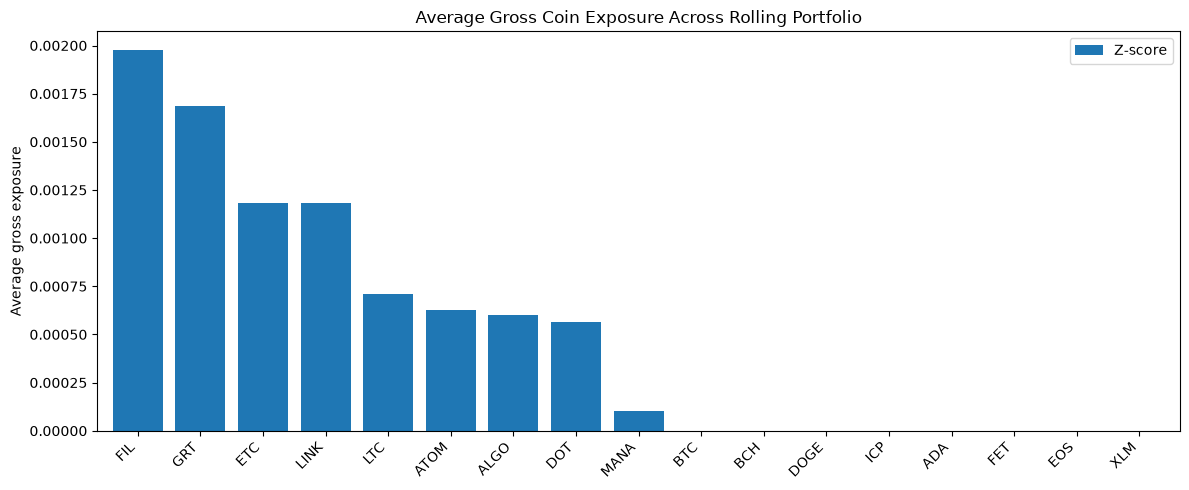

In [ ]:
z_coin_exposure = rolling_coin_exposure(z_pair_bts, z_w_applied)

coin_exp_df = z_coin_exposure.copy()
coin_exp_df.columns = ["Z-score"]
coin_exp_df = coin_exp_df.fillna(0).sort_values("Z-score", ascending=False)

display(coin_exp_df.head(10))

ax = coin_exp_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Average Gross Coin Exposure Across Rolling Portfolio")
ax.set_ylabel("Average gross exposure")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print("Z-score quarterly weights:")
display(z_w_applied.round(4))

print("\nAverage Z-score pair weights:")
display(z_w_applied.mean().sort_values(ascending=False).to_frame("Average Weight"))

Z-score quarterly weights:


,ADA/ALGO,DOGE/FET,LINK/ETC,ALGO/FIL,LTC/EOS,ETC/GRT,LINK/FIL,FIL/ETC,ICP/EOS,LTC/ALGO,...,LINK/ALGO,DOT/ETC,ATOM/ETC,BCH/ETC,FIL/GRT,ATOM/MANA,DOT/ATOM,ADA/XLM,DOGE/ATOM,DOGE/MANA
Quarter,,,,,,,,,,,,,,,,,,,,,
2024Q4,0.0000,0.2515,0.2966,0.1155,0.1089,0.1423,0.0852,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000,0.0000,0.0,0.0
2025Q1,0.0628,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5869,0.0818,0.0855,...,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000,0.0000,0.0,0.0
2025Q2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4677,0.0000,0.0000,...,0.0245,0.0392,0.0316,0.0,0.0783,0.0000,0.0000,0.0000,0.0,0.0
2025Q3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0275,0.0433,0.0404,0.0,0.0706,0.0707,0.1464,0.2792,0.0,0.0
2025Q4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,1.0000,0.0000,0.0,0.0



Average Z-score pair weights:


,Average Weight
DOT/ATOM,0.229277
FIL/ETC,0.210919
FIL/ICP,0.076098
LINK/ETC,0.059324
ADA/XLM,0.055832
DOGE/FET,0.050300
BCH/MANA,0.035498
FIL/GRT,0.029785
ETC/GRT,0.028458
ALGO/FIL,0.023097


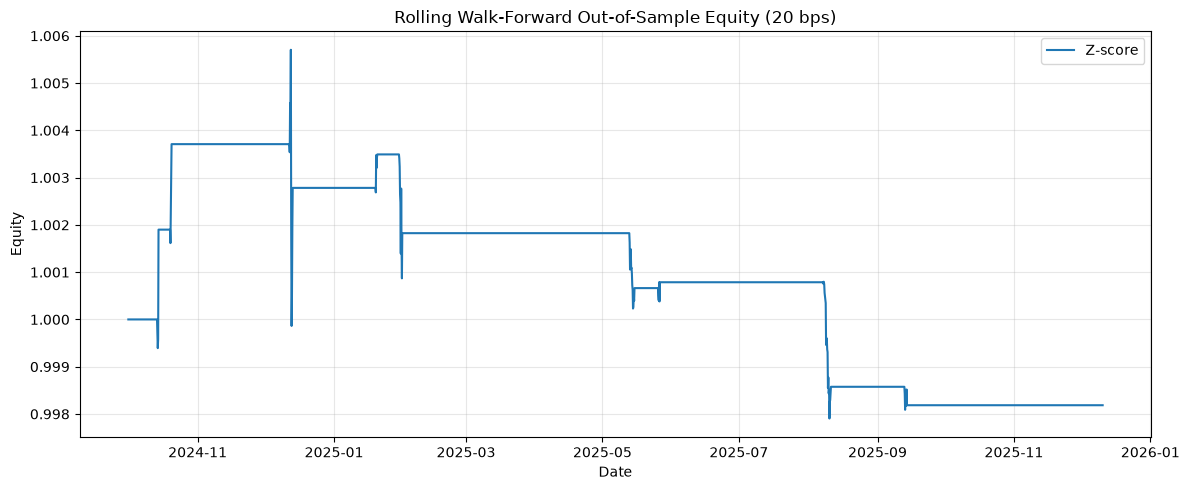

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(z_port_equity,label="Z-score")

plt.title(f"Rolling Walk-Forward Out-of-Sample Equity ({FEE_BPS_MAIN:.0f} bps)")

plt.xlabel("Date")
plt.ylabel("Equity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
p_train_best = train_best_z.copy()

candidate_rows = []
for a, b in pairs:
    candidate_rows.append(pair_summary(p_train_best, a.split("/")[0], b.split("/")[0]))

timeframe_pairs = pd.DataFrame(candidate_rows)
timeframe_pairs = timeframe_pairs.query("Corr > 0.8")
timeframe_pairs = timeframe_pairs.query("EG_Coint_Pvalue < 0.1")
timeframe_pairs = timeframe_pairs.query("Half_life >= 12 and Half_life <= 600")
timeframe_pairs = timeframe_pairs.query("Beta_Stability <= 0.35")
timeframe_pairs = timeframe_pairs.sort_values("Z_score_Crossings", ascending=False).reset_index(drop=True)

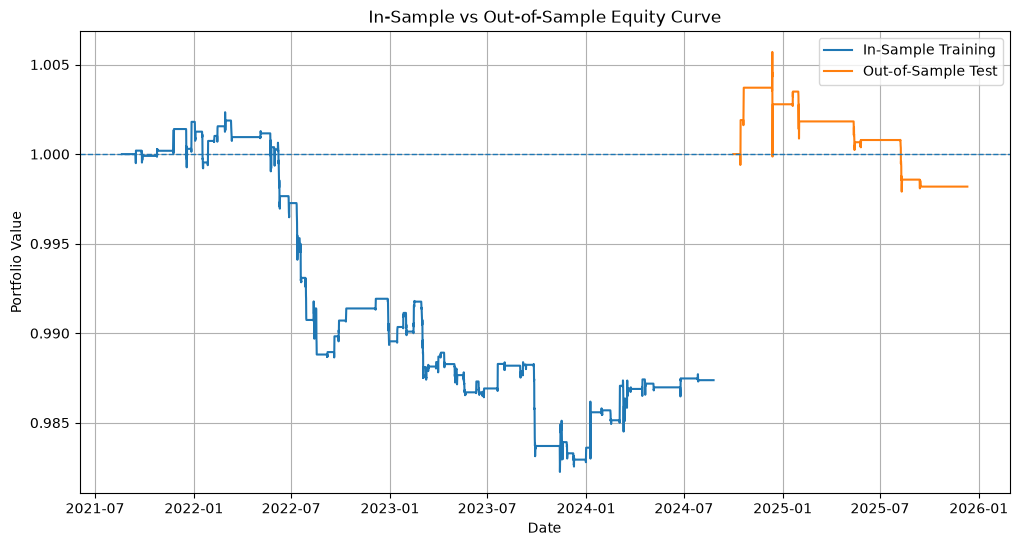

In [ ]:
# ==============================================
# In-Sample vs Out-of-Sample Equity Curves
# ==============================================

# Run the winning parameter set on the training period
train_bts, train_rets, train_metrics = run_pairs(
    train_best_z,
    timeframe_pairs,
    Z_ENTRY,
    FEE_BPS_MAIN,
    window=BEST_WINDOW_Z,
    min_persist=2,
    cooldown_bars=BEST_COOLDOWN_Z,
    timeframe_hours=BEST_TIMEFRAME_Z
)

# Build an equal-volatility training portfolio
train_rets_df = pd.concat(train_rets.values(), axis=1, join="inner").dropna(how="any")
train_inv_vol = 1 / train_rets_df.std().replace(0, np.nan)
train_weights = train_inv_vol / train_inv_vol.sum()
train_port_ret = train_rets_df.mul(train_weights, axis=1).sum(axis=1)

# Training equity curve
train_equity = (1 + train_port_ret).cumprod()

# Out-of-sample equity curve from the quarterly walk-forward
test_equity = z_port_equity.copy()

# Normalize both curves to start at 1
train_equity = train_equity / train_equity.iloc[0]
test_equity = test_equity / test_equity.iloc[0]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(train_equity.index, train_equity.values, label="In-Sample Training")
plt.plot(test_equity.index, test_equity.values, label="Out-of-Sample Test")
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.title("In-Sample vs Out-of-Sample Equity Curve")
plt.legend()
plt.grid(True)
plt.show()

# BTC Comparison

In [292]:
def hourly_to_daily(hourly_ret):
    equity = (1 + hourly_ret.fillna(0)).cumprod()
    daily_equity = equity.resample("1D").last().dropna()
    daily_ret = daily_equity.pct_change().dropna()
    return daily_ret

In [293]:
def daily_portfolio_metrics(daily_ret):
    daily_ret = daily_ret.dropna()
    equity = (1 + daily_ret.fillna(0)).cumprod()
    vol = daily_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (daily_ret.mean() / vol) * np.sqrt(365)
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (daily)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret),
    }

In [294]:
def benchmark_stats(port_daily_ret, btc_daily_ret):
    aligned = pd.concat(
        [port_daily_ret.rename("port"), btc_daily_ret.rename("btc")], axis=1
    ).dropna()
    X = sm.add_constant(aligned["btc"])
    model = sm.OLS(aligned["port"], X).fit()
    return {
        "Corr_to_BTC": aligned["port"].corr(aligned["btc"]),
        "Beta_to_BTC": model.params["btc"],
        "Alpha_Annualized": model.params["const"] * 365,
        "Alpha_tstat": model.tvalues["const"],
    }

In [295]:
btc_test_prices = test_prices.set_index("timestamp")["BTC"]
btc_daily_ret = btc_test_prices.resample("1D").last().dropna().pct_change().dropna()

z_daily_ret = hourly_to_daily(z_port_ret)

final_rows = {}
for name, daily_ret in [("Z-score", z_daily_ret)]:
    row = daily_portfolio_metrics(daily_ret)
    row.update(benchmark_stats(daily_ret, btc_daily_ret))
    final_rows[name] = row

final_summary = pd.DataFrame(final_rows).T
print(f"Final out-of-sample summary at {FEE_BPS_MAIN:.0f} bps, daily-aggregated:")
final_summary

Final out-of-sample summary at 20 bps, daily-aggregated:


/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_59904/3493332315.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned = pd.concat(


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-0.346329,-0.001815,-0.005513,435.0,0.043393,0.000429,-0.001709,-0.425985


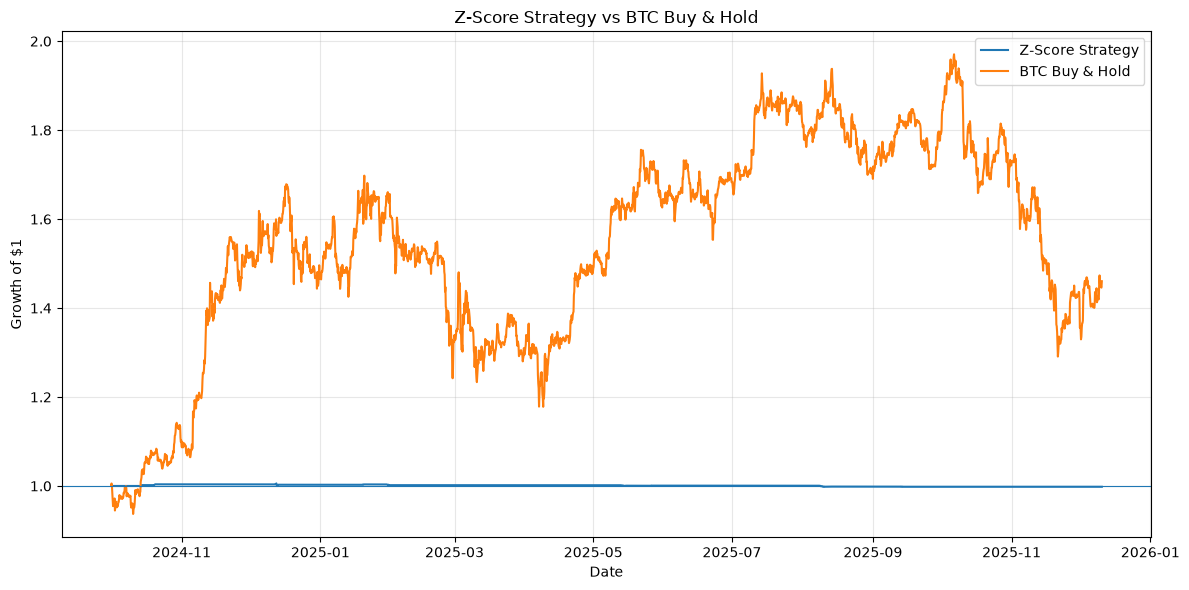

Strategy final value: $1.00
BTC final value:      $1.46
Strategy return:      -0.18%
BTC return:           46.04%


In [296]:
# ----------------------------------------------
# Compare strategy vs BTC buy-and-hold
# ----------------------------------------------

# Strategy cumulative equity
strategy_equity = (1 + z_port_ret.fillna(0)).cumprod()

# BTC returns over the same test period
btc_prices = prices_best_z[["timestamp", "BTC"]].copy()
btc_prices = btc_prices[btc_prices["timestamp"] >= first_z_date].set_index("timestamp")
btc_returns = btc_prices["BTC"].pct_change().fillna(0)

# BTC cumulative equity
btc_equity = (1 + btc_returns).cumprod()

# Align both series to the same timestamps
comparison = pd.concat(
    [strategy_equity.rename("Strategy"), btc_equity.rename("BTC")],
    axis=1
).dropna()

# Normalize both to $1
comparison = comparison / comparison.iloc[0]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(comparison.index, comparison["Strategy"], label="Z-Score Strategy")
plt.plot(comparison.index, comparison["BTC"], label="BTC Buy & Hold")
plt.axhline(1.0, linewidth=0.8)
plt.title("Z-Score Strategy vs BTC Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final outcomes
print(f"Strategy final value: ${comparison['Strategy'].iloc[-1]:.2f}")
print(f"BTC final value:      ${comparison['BTC'].iloc[-1]:.2f}")
print(f"Strategy return:      {(comparison['Strategy'].iloc[-1] - 1) * 100:.2f}%")
print(f"BTC return:           {(comparison['BTC'].iloc[-1] - 1) * 100:.2f}%")

In [297]:
strategy_row = daily_portfolio_metrics(daily_ret)
strategy_row.update(benchmark_stats(daily_ret, btc_daily_ret))

btc_row = daily_portfolio_metrics(btc_daily_ret)

# Fill columns that only make sense for the strategy
btc_row.update({
    "Corr_to_BTC": 1.0,
    "Beta_to_BTC": 1.0,
    "Alpha_Annualized": np.nan,
    "Alpha_tstat": np.nan
})

comparison = pd.DataFrame({
    "Z-score": strategy_row,
    "BTC Buy & Hold": btc_row
}).T

display(comparison.round(4))

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_59904/3493332315.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned = pd.concat(


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-0.3463,-0.0018,-0.0055,435.0,0.0434,0.0004,-0.0017,-0.426
BTC Buy & Hold,0.8660,0.4473,-0.3210,472.0,1.0000,1.0000,NaN,NaN
